# Project 13: Causal Inference vs Prediction

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Given observational data on a marketing campaign: Task: Estimate causal effect using matching or regression; Compare with predictive model results; Explain discrepancies

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Prediction asks 'what label is likely?' Causal inference asks 'what would change if we intervened?' Those answers can differ, and observational data alone cannot settle causation.

## Part 1 — Introduction

THERE IS NO MARKETING CAMPAIGN OR RANDOMISED TREATMENT HERE. The analogue treatment is high vs low Wind_Speed (median split, observational only), outcome is temp_mean(c), confounders are Pressure, global_radiation and Wind_Bearing. No causal effect is claimed as proven; unmeasured confounding remains possible.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Predictive model vs naive association

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
df=df_full.sample(n=25000, random_state=42).reset_index(drop=True)
df["treatment"]=(df["Wind_Speed"]>df["Wind_Speed"].median()).astype(int)
print("Treatment (high Wind_Speed) rate:", round(df["treatment"].mean(),4))
print("Naive mean temp_mean: high wind", round(df.loc[df["treatment"]==1,"temp_mean(c)"].mean(),3), "low wind", round(df.loc[df["treatment"]==0,"temp_mean(c)"].mean(),3), "difference", round(df.loc[df["treatment"]==1,"temp_mean(c)"].mean()-df.loc[df["treatment"]==0,"temp_mean(c)"].mean(),3))
Xtr,Xte,ytr,yte=train_test_split(df[FEATURES], df[TARGET], test_size=0.25, random_state=42, stratify=df[TARGET])
rf=RandomForestClassifier(n_estimators=120, random_state=42, n_jobs=-1); rf.fit(Xtr,ytr); print("Predictive RF accuracy for normalized_label:", round(accuracy_score(yte, rf.predict(Xte)),4))
print("RF feature importances:\n", pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False).round(4).to_string())

Treatment (high Wind_Speed) rate: 0.4987
Naive mean temp_mean: high wind 12.527 low wind 12.897 difference -0.37


Predictive RF accuracy for normalized_label: 0.8986
RF feature importances:
 Wind_Speed          0.3785
global_radiation    0.1985
temp_max(c)         0.1112
temp_min(c)         0.0956
temp_mean(c)        0.0904
Pressure            0.0785
Wind_Bearing        0.0473


## Part 4 — Regression adjustment and propensity stratification

In [3]:
# Regression adjustment is implemented in the next cell with sklearn only; statsmodels is not required.
print("Regression adjustment, propensity stratification and matching are implemented in the next cell (sklearn only).")

Regression adjustment, propensity stratification and matching are implemented in the next cell (sklearn only).


## Part 5 — Matching and interpretation (statsmodels-free fallback)

In [4]:
# This cell avoids a hard statsmodels dependency: OLS via sklearn + propensity via logistic regression + stratification + nearest-neighbour matching
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
conf=["Pressure","global_radiation","Wind_Bearing"]
Xc=StandardScaler().fit_transform(df[conf])
# Regression adjustment
lr=LinearRegression(); lr.fit(np.column_stack([df["treatment"], Xc]), df["temp_mean(c)"]); print("Regression-adjusted treatment coefficient (high vs low Wind_Speed, temp_mean):", round(float(lr.coef_[0]),4))
# Propensity scores
ps_model=LogisticRegression(max_iter=1000); ps_model.fit(Xc, df["treatment"]); df["ps"]=ps_model.predict_proba(Xc)[:,1]
print("Propensity overlap: treated PS mean", round(df.loc[df["treatment"]==1,"ps"].mean(),3), "control PS mean", round(df.loc[df["treatment"]==0,"ps"].mean(),3))
# Stratification into quintiles
df["ps_stratum"]=pd.qcut(df["ps"], 5, labels=False, duplicates="drop"); diffs=[]
for s, grp in df.groupby("ps_stratum"):
    if grp["treatment"].nunique()==2: diffs.append((len(grp), grp.loc[grp["treatment"]==1,"temp_mean(c)"].mean()-grp.loc[grp["treatment"]==0,"temp_mean(c)"].mean()))
wavg=sum(n*d for n,d in diffs)/sum(n for n,d in diffs); print("Propensity-stratified (quintile-weighted) difference:", round(float(wavg),4), "strata:", [(int(n),round(float(d),3)) for n,d in diffs])
# Nearest-neighbour matching on propensity (treated to nearest control)
treated=df[df["treatment"]==1]; control=df[df["treatment"]==0]
nn=NearestNeighbors(n_neighbors=1).fit(control[["ps"]].values); dist, idx=nn.kneighbors(treated[["ps"]].values)
matched_diff=float(treated["temp_mean(c)"].mean()-control.iloc[idx.flatten()]["temp_mean(c)"].mean()); print("Nearest-neighbour matching difference (treated mean - matched control mean):", round(matched_diff,4))
print("DISCREPANCY EXPLANATION: The predictive model ranks Wind_Speed by how much it helps predict the label, which is not the same as the effect of changing Wind_Speed on temperature. Confounding (e.g. pressure/radiation differing between high- and low-wind rows) moves the naive difference away from the adjusted estimates, and unmeasured factors could still bias all observational estimates.")

Regression-adjusted treatment coefficient (high vs low Wind_Speed, temp_mean): -0.037
Propensity overlap: treated PS mean 0.513 control PS mean 0.484
Propensity-stratified (quintile-weighted) difference: -0.1138 strata: [(5000, -0.251), (5000, 0.119), (5000, 0.193), (5000, -0.181), (5000, -0.45)]
Nearest-neighbour matching difference (treated mean - matched control mean): -0.1885
DISCREPANCY EXPLANATION: The predictive model ranks Wind_Speed by how much it helps predict the label, which is not the same as the effect of changing Wind_Speed on temperature. Confounding (e.g. pressure/radiation differing between high- and low-wind rows) moves the naive difference away from the adjusted estimates, and unmeasured factors could still bias all observational estimates.


## Additional visualization

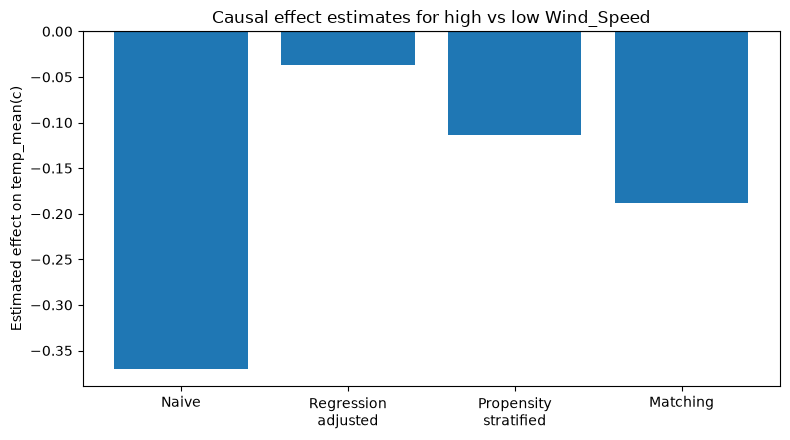

Effect estimates plotted: [-0.3704, -0.037, -0.1138, -0.1885]


In [5]:
# Effect estimates compared: naive, regression-adjusted, propensity-stratified, matching
naive=float(df.loc[df["treatment"]==1,"temp_mean(c)"].mean()-df.loc[df["treatment"]==0,"temp_mean(c)"].mean())
vals=[naive, float(lr.coef_[0]), float(wavg), float(matched_diff)]
plt.bar(["Naive","Regression\nadjusted","Propensity\nstratified","Matching"], vals); plt.axhline(0, color="black", linewidth=0.8); plt.ylabel("Estimated effect on temp_mean(c)"); plt.title("Causal effect estimates for high vs low Wind_Speed"); plt.tight_layout(); plt.show()
print("Effect estimates plotted:", [round(v,4) for v in vals])

## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.